In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from matplotlib import rc
rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
rc('text', usetex=True)

In [ ]:
df1 = pd.read_csv("globular_clusters.csv")
df1 = df1[0:-3]
harris_p1 = pd.read_csv('HarrisPartI.csv')
harris_p2 = pd.read_csv('HarrisPartII.csv')
harris_p3 = pd.read_csv('HarrisPartIII.csv')

In [ ]:
R_gc = pd.to_numeric(harris_p1['R_gc'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
name = harris_p1['ID']
R_Sun = pd.to_numeric(harris_p1['R_Sun'],errors='coerce')
sig_v = pd.to_numeric(harris_p3['sig_v'],errors='coerce')
v_r = pd.to_numeric(harris_p3['v_r'],errors='coerce')
mtlc = pd.to_numeric(harris_p2['[Fe/H]'],errors='coerce')
M_V = pd.to_numeric(harris_p2['M_V,t'],errors='coerce')
v_LSR = pd.to_numeric(harris_p3['v_LSR'],errors='coerce')
L = pd.to_numeric(harris_p1['L'],errors='coerce')
B = pd.to_numeric(harris_p1['B'],errors='coerce')
r_h = pd.to_numeric(harris_p3['r_h'],errors='coerce')
l = L*np.pi/180
b = B*np.pi/180
V0 = 220
v_GSR = v_LSR + V0*np.sin(l)*np.cos(b)

In [ ]:
# G = 4.3009172706*10**(-6) # kpc * (km/s)^2 / M_o
# R = r_h*np.pi/(60*180)*R_Sun # kpc
# M = sig_v**2*R/G # M_o
# Mlog = np.log10(M)
# Rlog = np.log10(R_gc)
# vlog = np.log10(abs(v_GSR)/sig_v)
# mask = np.isfinite(Rlog) & np.isfinite(vlog) & np.isfinite(Mlog)

: 

In [ ]:
def f(x,A,B):
    return A*x+B

p,c = curve_fit(f,vlog[mask],Mlog[mask])
Delta = Mlog - f(vlog,*p)
S_Delta = np.sqrt(1/(len(mask)-2)*np.sum(Delta**2))
xfit = np.linspace(vlog[mask].min(),vlog[mask].max(),1000)
sig_fit = np.sqrt(c[0,0]*xfit**2+c[1,1]+2*c[0,1]*xfit)

sig_pred = np.sqrt(sig_fit**2+S_Delta**2)
yfit = f(xfit,*p)
lower2 = yfit-1.96*sig_pred
upper2 = yfit+1.96*sig_pred
lower3 = yfit-3/2*1.96*sig_pred
upper3 = yfit+3/2*1.96*sig_pred
z = abs(Delta/S_Delta)

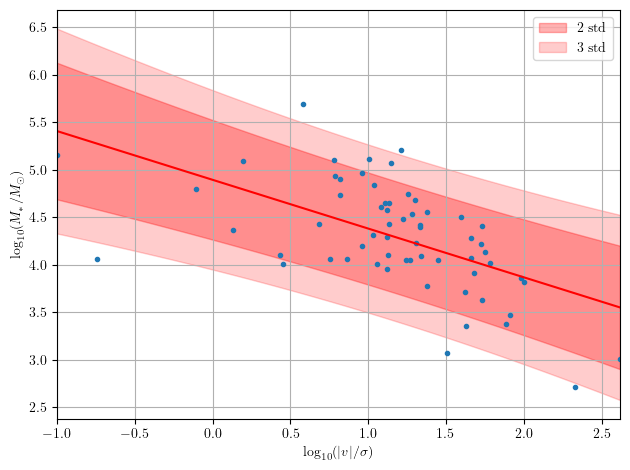

In [ ]:
plt.figure()
plt.plot(vlog,Mlog,'.')
plt.plot(xfit, yfit, color='red')
plt.fill_between(xfit, lower2, upper2,
                 color='red', alpha=0.3,
                 label=r'$2$ std')
plt.fill_between(xfit, lower3, upper3,
                 color='red', alpha=0.2,
                 label=r'$3$ std')
plt.ylabel(r'$\log_{10}(M_*/M_\odot)$')
plt.xlabel(r'$\log_{10}(|v|/\sigma)$')
plt.legend()
plt.grid()
plt.tight_layout()
# plt.gca().invert_xaxis()
# plt.title(r'Distribution of globular clusters')
plt.xlim(vlog[mask].min(),vlog[mask].max())
plt.show()

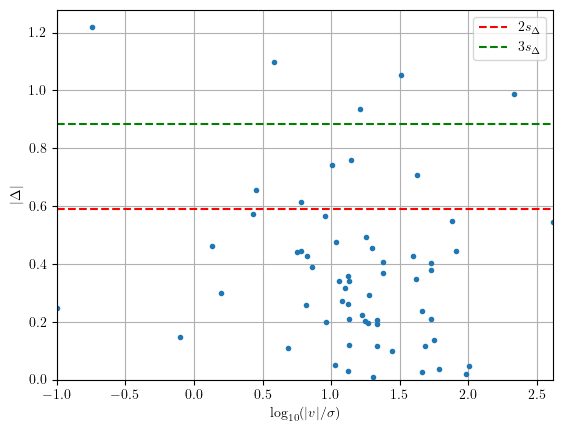

In [ ]:
plt.figure()
plt.plot(vlog[mask],abs(Delta)[mask],'.')
plt.plot(xfit,xfit*0+2*S_Delta,'--',color='red',label=r'$2s_\Delta$')
plt.plot(xfit,xfit*0+3*S_Delta,'--',color='green',label=r'$3s_\Delta$')
plt.xlim(vlog[mask].min(),vlog[mask].max())
plt.xlabel(r'$\log_{10}(|v|/\sigma)$')
plt.ylabel(r'$|\Delta|$')
plt.ylim(0)
plt.grid()
plt.legend()
plt.show()

In [ ]:
print(name[mask][z > 3])

28     NGC 5139
78     NGC 6366
132    NGC 6712
133    NGC 6715
155      Pal 13
Name: ID, dtype: object
